<h1><font color='blue'>Sistemas de Recomendação - Busca e Recomendação baseada em conteúdo</font></h1>

---

## Visão geral

Este notebook explora técnicas de **recuperação de informação** e **sistemas de recomendação baseados em conteúdo** usando dados de filmes.

O objetivo é comparar formas de representar textos, recuperar itens a partir de consultas e combinar sinais lexicais e semânticos para produzir rankings e recomendações.

O trabalho foi desenvolvido como prática acadêmica na especialização em Inteligência Artificial e Machine Learning, com foco no entendimento dos conceitos e na implementação de protótipos em Python.

## Objetivos de aprendizagem

- Representar filmes a partir de títulos, gêneros e tags textuais.
- Implementar busca lexical com TF-IDF e BM25.
- Gerar embeddings de texto com Sentence-BERT e recuperar filmes por similaridade semântica.
- Combinar rankings lexicais e semânticos por meio de Reciprocal Rank Fusion (RRF).
- Aplicar um reranker para reordenar os candidatos recuperados.
- Construir recomendações baseadas em conteúdo, tanto não personalizadas quanto personalizadas a partir do perfil de gêneros de um usuário.
- Analisar como a combinação de similaridade entre itens e afinidade com o perfil do usuário altera as recomendações.

## Dados e preparação

O notebook utiliza conjuntos de dados de filmes e avaliações. Cada filme é transformado em um documento textual composto por **título, gêneros e tags**. A preparação inclui conversão para minúsculas, remoção de acentos, substituição de caracteres especiais e normalização de espaços.

Na etapa de personalização, as avaliações são usadas para identificar filmes bem avaliados por cada usuário e construir um perfil de preferência por gênero.

## Técnicas implementadas

1. Busca lexical com TF-IDF
2. Busca lexical com BM25
3. Busca semântica com embeddings
4. Recuperação híbrida com RRF
5. Reordenação com reranker
6. Recomendação baseada em conteúdo não personalizada



# Imports

In [1]:
from  IPython.display import Image

# Um pouco de recuperação de informação

Seja pesquisando o título de um filme ou os filmes de um determinado ator ou de um determinado gênero ou produtos que você procura ou vídeos que deseja assistir, além das recomendações propriamente ditas, busca é uma ferramenta importante para se encontrar os itens desejados.

Como incorporar um mecanismo de busca capaz de encontrar os itens procurados, considerando diversas fontes de evidências? 

A resposta é usando um **Sistema de Recuperação de Informação**.

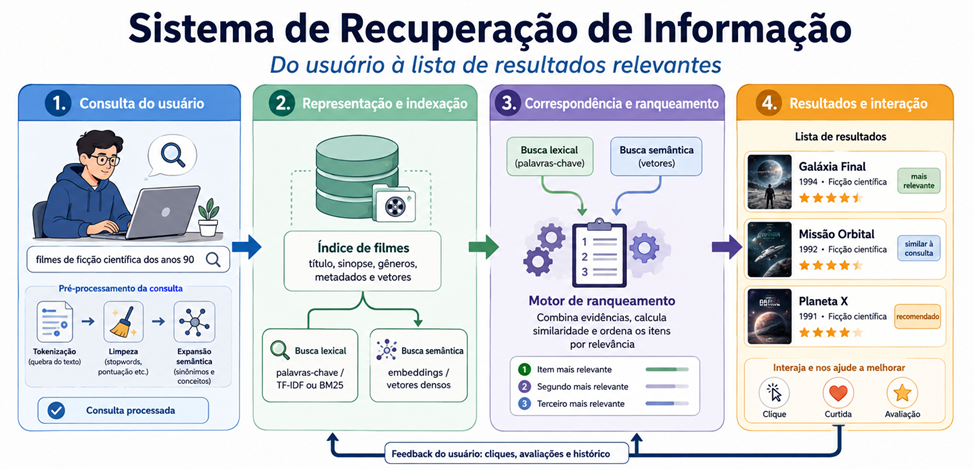

O modelo de espaço vetorial ou simplesmente modelo vetorial, é, sem dúvida, o modelo mais conhecido em recuperação de informação.

A idéia central do modelo vetorial é representar algebricamente, como vetores em um espaço euclidiano *t*-dimensional, onde $t$ é o número de termos distintos da coleção, o conjunto de termos de uma consulta
$q$ e dos documentos de uma coleção $D$, conforme figura abaixo:



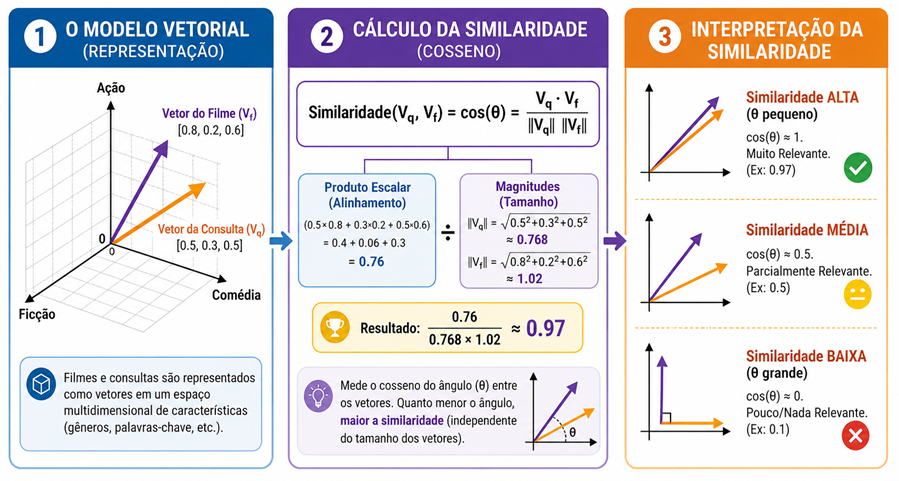

### 1 Modelo Vetorial

* Em um sistema de recuperação de informação, itens são representados em um Espaço Vetorial
    - Imagine um gráfico onde cada eixo representa uma característica (Ex: gênero, palavra-chave, ator etc.) 
    - Cada item é um vetor nesse espaço

* Quando o usuário faz uma busca, a consulta também é convertida em um vetor

* Para se encontrar os itens relevantes para a busca, calcula-se a “proximidade” entre os vetores da consulta e dos itens

### 2 Cálculo da Similaridade

* Usa-se a similaridade do cosseno de cada item com a consulta para calcular a proximidade dos vetores
* Mede o cosseno do ângulo entre o vetor da consulta e os vetores de cada item
	- Ângulo pequeno (Cosseno ≈ 1) → Alta similaridade
	- Ângulo grande (Cosseno ≈ 0) → Baixa similaridade
* Ordena-se os itens de acordo com a ordem decrescente de similaridade

### 3 Interpretação do Cálculo da Similaridade

* Para produzir o ranking final de itens em resposta a uma consulta, os itens são ordenados na ordem inversa do valor da similaridade de cada item com a consulta

### Representação vetorial

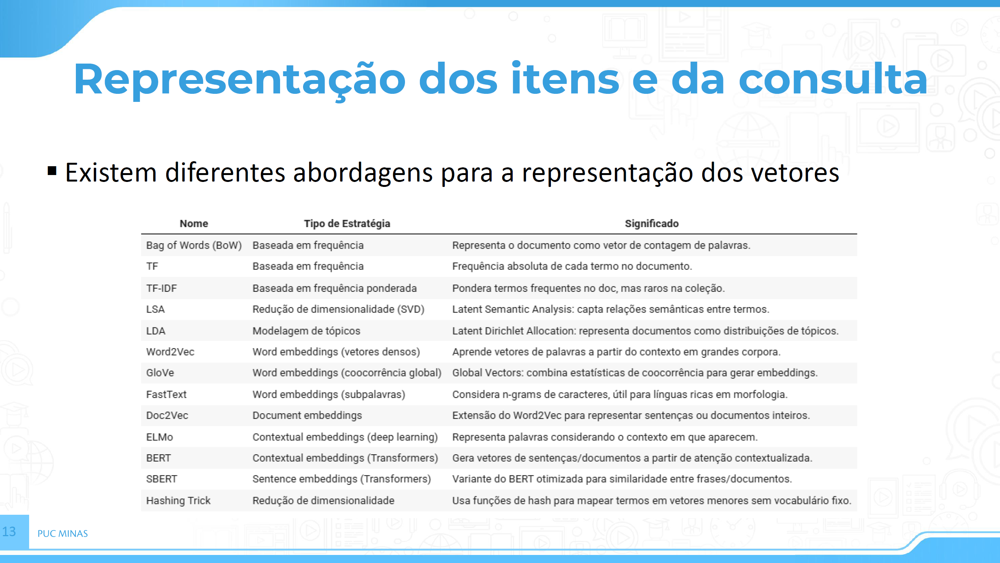

In [2]:
Image('./imagens/aula_04_001.png')

Existem diferentes estratégias para representação vetorial de textos, conforme pode ser visto na figura a seguir.

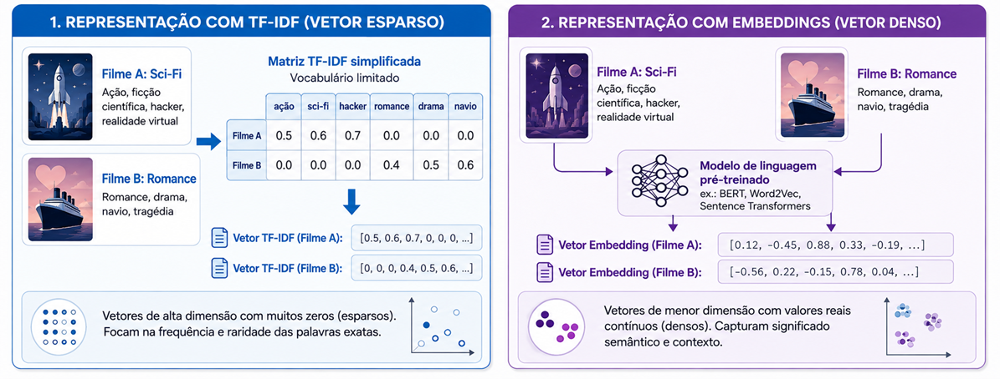

# Busca usando TF-IDF

##  Representando filmes como vetores

### Lendo o dataset de filmes

In [3]:
import re
import warnings
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer, CrossEncoder

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

In [4]:
# dataset com as informação dos filmes
movies = pd.read_csv('./datasets/movies_imdb.csv', header=0, encoding='latin-1', low_memory=False)
movies.head()

,movieId,title,genres,tags,tag_count,vote_count,vote_average,imdb_score
0,1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy,fun pixar,2,215,3.9209,3.8945
1,2,Jumanji,Adventure|Children|Fantasy,fantasy magic_board_game game robin_williams,4,110,3.4318,3.4190
2,3,Grumpier Old Men,Comedy|Romance,old moldy,2,52,3.2596,3.2600
3,4,Waiting to Exhale,Comedy|Drama|Romance,NaN,0,7,2.3571,2.8664
4,5,Father of the Bride Part II,Comedy,pregnancy remake,2,49,3.0714,3.1011


In [5]:
# dataset com as informação das notas dos filmes
ratings = pd.read_csv('./datasets/ratings_imdb.csv', header=0, encoding='latin-1', low_memory=False)
ratings['timestamp'] = pd.to_datetime(ratings['timestamp'], unit='s')
ratings.head()

,userId,movieId,rating,timestamp
0,1,1,4.0000,2000-07-30 18:45:03
1,1,3,4.0000,2000-07-30 18:20:47
2,1,6,4.0000,2000-07-30 18:37:04
3,1,47,5.0000,2000-07-30 19:03:35
4,1,50,5.0000,2000-07-30 18:48:51


In [6]:
movies["tags"] = movies["tags"].fillna("")
movies = movies.set_index("movieId")

print(f"Filmes: {len(movies)}")
print(f"Avaliações: {len(ratings)}")
print(f"Usuários: {ratings['userId'].nunique()}")

display(movies.head())
display(ratings.head())

Filmes: 9724
Avaliações: 100836
Usuários: 610


,title,genres,tags,tag_count,vote_count,vote_average,imdb_score
movieId,,,,,,,
1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy,fun pixar,2,215,3.9209,3.8945
2,Jumanji,Adventure|Children|Fantasy,fantasy magic_board_game game robin_williams,4,110,3.4318,3.4190
3,Grumpier Old Men,Comedy|Romance,old moldy,2,52,3.2596,3.2600
4,Waiting to Exhale,Comedy|Drama|Romance,,0,7,2.3571,2.8664
5,Father of the Bride Part II,Comedy,pregnancy remake,2,49,3.0714,3.1011


,userId,movieId,rating,timestamp
0,1,1,4.0000,2000-07-30 18:45:03
1,1,3,4.0000,2000-07-30 18:20:47
2,1,6,4.0000,2000-07-30 18:37:04
3,1,47,5.0000,2000-07-30 19:03:35
4,1,50,5.0000,2000-07-30 18:48:51


Tags --> Informações que os usuários inseriram 

Formatando a lista de documentos

In [7]:
def normalizar_texto(texto):
    texto = str(texto).lower()
    texto = unicodedata.normalize("NFKD", texto)
    texto = texto.encode("ascii", "ignore").decode("utf-8")
    texto = re.sub(r"[^a-z0-9\s]", " ", texto)
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto


def movie_to_document(row):
    generos = str(row["genres"]).replace("|", " ")
    return normalizar_texto(
        f"{row['title']} {generos} {row['tags']}"
    )


documents = movies.apply(movie_to_document, axis=1).tolist()
documents[:5]

['toy story adventure animation children comedy fantasy fun pixar',
 'jumanji adventure children fantasy fantasy magic board game game robin williams',
 'grumpier old men comedy romance old moldy',
 'waiting to exhale comedy drama romance',
 'father of the bride part ii comedy pregnancy remake']

In [8]:
len(documents)

9724

### Representando filmes como vetores TF-IDF


A classe `TfidfVectorizer` gera uma matriz com os valores do peso de cada termo x documento, baseado no TF-IDF, conforme definido abaixo:

$$peso(t_i,d_j) = \frac{w_{i,j}}{\sqrt{\sum_{i=1}^{t} w^{2}_{i,j}}}$$
<br>
onde $w_{i,j}$ é definido comumente por $\left( 1 + \log tf_{i,j} \right) \times \log {\left( 1 + \frac{N}{df_{i}} \right)}$

Considera a frequencia do termo que a palavra aparece bem como a frequencia inversa da palavra considerando todos os filmes

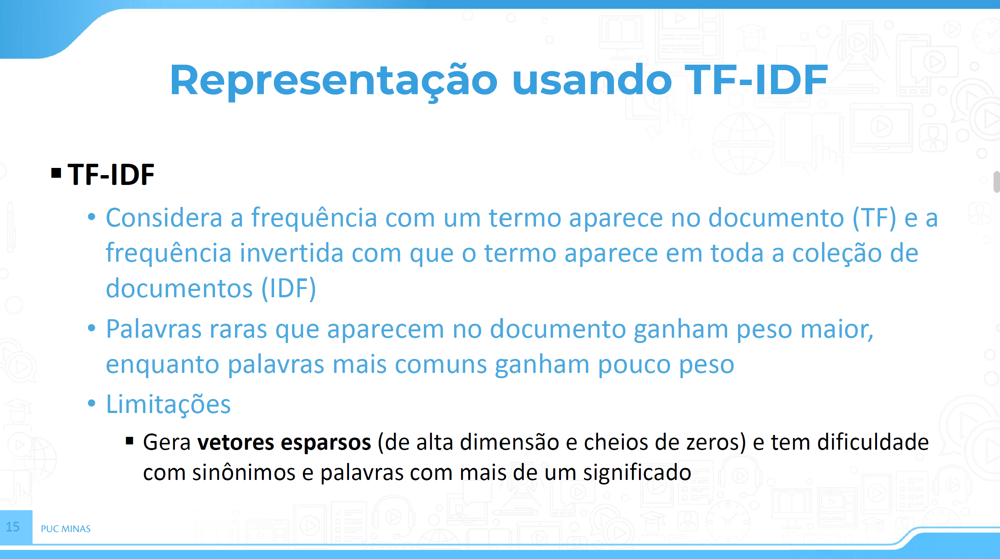

In [9]:
Image('./imagens/aula_04_002.png')

#### Gerando os vetores TF-IDF

In [10]:
tfidf = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    sublinear_tf=True
)

tfidf_matrix = tfidf.fit_transform(documents)

print( "Dimensão da matriz TF-IDF:", tfidf_matrix.shape)
print( "Tipo:", type(tfidf_matrix) )

Dimensão da matriz TF-IDF: (9724, 10049)
Tipo: <class 'scipy.sparse._csr.csr_matrix'>


Exemplo da matriz TF-IDF

Para os 9724 tem-se o Espaço vetorial de 10049 termos  (10049 colunas)

Cada linha é a representação vetorial de um filme. 
* o vetor tem mais de 10 mil dimensões

Essa etapa corresponde a etapa de indexação dos textos em 
* Mudança de texto para a representação vetorial

In [11]:
tfidf_demo = pd.DataFrame(
    tfidf_matrix[:5].toarray(),
    columns=tfidf.get_feature_names_out()
)

# Mostra somente termos presentes nos 5 primeiros documentos.
tfidf_demo = tfidf_demo.loc[:, (tfidf_demo != 0).any()]

tfidf_demo.round(2)

,adventure,animation,board,bride,children,comedy,drama,exhale,fantasy,father,fun,game,grumpier,ii,jumanji,magic,men,moldy,of,old,part,pixar,pregnancy,remake,robin,romance,story,the,to,toy,waiting,williams
0,0.1800,0.2200,0.0000,0.0000,0.2100,0.1100,0.0000,0.0000,0.2100,0.0000,0.4600,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.0000,0.0000,0.0000,0.3300,0.0000,0.0000,0.4900,0.0000,0.0000
1,0.1300,0.0000,0.4000,0.0000,0.1600,0.0000,0.0000,0.0000,0.2600,0.0000,0.0000,0.4900,0.0000,0.0000,0.4000,0.3200,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.3300,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.3500
2,0.0000,0.0000,0.0000,0.0000,0.0000,0.1000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.4900,0.0000,0.0000,0.0000,0.3100,0.4900,0.0000,0.6400,0.0000,0.0000,0.0000,0.0000,0.0000,0.1400,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
3,0.0000,0.0000,0.0000,0.0000,0.0000,0.1400,0.1300,0.6700,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.2000,0.0000,0.0000,0.3300,0.0000,0.6000,0.0000
4,0.0000,0.0000,0.0000,0.4100,0.0000,0.1100,0.0000,0.0000,0.0000,0.4000,0.0000,0.0000,0.0000,0.3100,0.0000,0.0000,0.0000,0.0000,0.1800,0.0000,0.3500,0.0000,0.4600,0.4300,0.0000,0.0000,0.0000,0.1200,0.0000,0.0000,0.0000,0.0000


#### Executando consultas

A partir da matriz com os valores de TF-IDF será possível executar consultas recuperando os documentos relevantes, de acordo com palavras chaves informadas pelo usuário.

In [12]:
def search_tfidf(query, top_k=10):
    query_vector = tfidf.transform([normalizar_texto(query)])
    # Similariadade da consulta com todos os filmes
    scores = cosine_similarity(query_vector, tfidf_matrix)[0]

    # ordena em ordem decrescente
    ordem = np.argsort(scores)[::-1][:top_k]

    resultado = movies.iloc[ordem][["title", "genres", "tags"]].copy()
    resultado["score_tfidf"] = scores[ordem]

    return resultado

# caixa de busca de acordo com texto inserido pelo usuário
search_tfidf("toy story children", top_k=5)

,title,genres,tags,score_tfidf
movieId,,,,
78499,Toy Story 3,Adventure|Animation|Children|Comedy|Fantasy|IMAX,,0.7980
4929,"Toy, The",Comedy,,0.7375
1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy,fun pixar,0.6300
5843,Toy Soldiers,Action|Drama,,0.5418
3114,Toy Story 2,Adventure|Animation|Children|Comedy|Fantasy,tom_hanks original pixar animation disney funny sequel,0.4394


**score_tfidf**

--> Similaridade do coseno calculado pelo vetor tf-idf

--> Ordem de decrecente dos filmes
* Correspode os cinco filmes mais relevantes de acordo com a consulta inserida

--> O calculo do coseno varia de 0 a 1 --> o calculo do coseno de certa forma já é normalizado

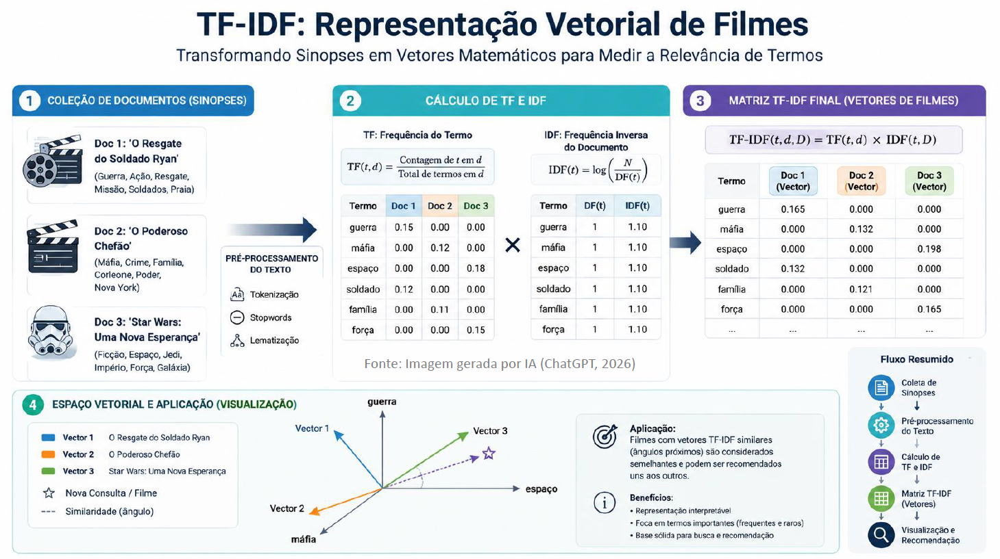

In [13]:
Image('./imagens/aula_04_003.png')

In [14]:
search_tfidf("dead man drama", top_k=5)

,title,genres,tags,score_tfidf
movieId,,,,
714,Dead Man,Drama|Mystery|Western,,0.7817
40412,Dead Man's Shoes,Crime|Thriller,,0.6144
2169,Dead Man on Campus,Comedy,,0.5717
101739,Evil Dead,Horror,,0.4542
6967,Dead of Night,Horror|Mystery,,0.4364


In [15]:
search_tfidf("mafia", top_k=5)

,title,genres,tags,score_tfidf
movieId,,,,
16,Casino,Crime|Drama,mafia,0.6373
858,"Godfather, The",Crime|Drama,mafia,0.6201
1213,Goodfellas,Crime|Drama,mafia,0.5969
2249,My Blue Heaven,Comedy,mafia,0.5541
2027,Jane Austen's Mafia!,Comedy|Crime,,0.5474


#### A limitação do nível léxico

Compare as consultas:

```text
space adventure
journey through the cosmos
```

Elas podem expressar intenções semanticamente semelhantes, mas não necessariamente usam as mesmas palavras.

In [16]:
display(search_tfidf("space adventure", top_k=5))
display(search_tfidf("journey through the cosmos", top_k=5))

,title,genres,tags,score_tfidf
movieId,,,,
1831,Lost in Space,Action|Adventure|Sci-Fi,,0.6155
3827,Space Cowboys,Action|Adventure|Comedy|Sci-Fi,,0.5804
1200,Aliens,Action|Adventure|Horror|Sci-Fi,horror action space_craft sci-fi suspense space_travel aliens space,0.5481
121007,Space Buddies,Adventure|Children|Fantasy|Sci-Fi,,0.5416
128902,The Forgotten Space,Documentary,,0.5149


,title,genres,tags,score_tfidf
movieId,,,,
171495,Cosmos,(no genres listed),,0.4324
26791,Shining Through,Drama|Romance|Thriller|War,,0.3315
2057,"Incredible Journey, The",Adventure|Children,,0.3211
3055,Felicia's Journey,Thriller,,0.2893
143525,Chasuke's Journey,Comedy|Drama,,0.2892


O TF-IDF representa documentos como vetores esparsos, ponderando os termos de acordo com sua frequência no documento e sua raridade na coleção. 

A consulta também é vetorizada e comparada aos filmes usando similaridade do cosseno.

<font color = 'red'>**Ponto principal:**</font> funciona bem quando os termos da consulta correspondem aos termos presentes nos documentos, mas pode ter dificuldade com paráfrases ou expressões semanticamente próximas que usam palavras diferentes.

### Representando filmes usando BM25

O BM25 (Best Matching 25) é um algoritmo de ranqueamento amplamente consolidado na área de recuperação de informação, atuando como uma evolução inteligente e robusta do tradicional TF-IDF.

O BM25 é outra técnica de recuperação lexical. Em relação ao TF-IDF, ele introduz mecanismos como:

- saturação da frequência do termo;
- normalização relacionada ao comprimento do documento.

Para esta prática, pense no BM25 como um **retriever lexical robusto**.

#### Criando o índice esparso BM25

In [17]:
# Criando a representação BM25

tokenized_docs = [doc.split() for doc in documents]
bm25 = BM25Okapi(tokenized_docs)

Passa-se uma coleção de documentos pelo atributo corpus

In [18]:
tokenized_docs[:5]

[['toy',
  'story',
  'adventure',
  'animation',
  'children',
  'comedy',
  'fantasy',
  'fun',
  'pixar'],
 ['jumanji',
  'adventure',
  'children',
  'fantasy',
  'fantasy',
  'magic',
  'board',
  'game',
  'game',
  'robin',
  'williams'],
 ['grumpier', 'old', 'men', 'comedy', 'romance', 'old', 'moldy'],
 ['waiting', 'to', 'exhale', 'comedy', 'drama', 'romance'],
 ['father',
  'of',
  'the',
  'bride',
  'part',
  'ii',
  'comedy',
  'pregnancy',
  'remake']]

In [19]:
# fez a indexação e o preparo para utilizar os documentos (filmes)
# corresponde a matrix tf-idf
bm25

#### Executando consultas

In [20]:
def search_bm25(query, top_k=10):
    query_tokens = normalizar_texto(query).split()

    # pega os scores de toda coleção e compara com a query
    scores = bm25.get_scores(query_tokens)

    ordem = np.argsort(scores)[::-1][:top_k]

    resultado = movies.iloc[ordem][["title", "genres","tags"]].copy()
    resultado["score_bm25"] = scores[ordem]

    return resultado


search_bm25("toy story children", top_k=5)

,title,genres,tags,score_bm25
movieId,,,,
1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy,fun pixar,12.3432
78499,Toy Story 3,Adventure|Animation|Children|Comedy|Fantasy|IMAX,,12.3432
4929,"Toy, The",Comedy,,9.8030
5843,Toy Soldiers,Action|Drama,,8.9692
3114,Toy Story 2,Adventure|Animation|Children|Comedy|Fantasy,tom_hanks original pixar animation disney funny sequel,8.7062


Existe uma diferença do scores com relação score_tfidf

-->  O score_bm25 não é normalizado 

--> quanto maior melhor

--> não tem limite superior

In [21]:
search_bm25("dead man drama", top_k=5)

,title,genres,tags,score_bm25
movieId,,,,
714,Dead Man,Drama|Mystery|Western,,10.0136
2169,Dead Man on Campus,Comedy,,9.7804
40412,Dead Man's Shoes,Crime|Thriller,,9.0694
36,Dead Man Walking,Crime|Drama,death_penalty nun,8.1070
45722,Pirates of the Caribbean: Dead Man's Chest,Action|Adventure|Fantasy,,6.6517


In [22]:
search_bm25("mafiax", top_k=5)

,title,genres,tags,score_bm25
movieId,,,,
193609,Andrew Dice Clay: Dice Rules,Comedy,,0.0000
193587,Bungo Stray Dogs: Dead Apple,Action|Animation,,0.0000
193585,Flint,Drama,,0.0000
193583,No Game No Life: Zero,Animation|Comedy|Fantasy,,0.0000
193581,Black Butler: Book of the Atlantic,Action|Animation|Comedy|Fantasy,,0.0000


<font color='red'>**Cuidado com a grafia, pois a abordagem de correspondencia é lexical.**</f>

    --> Mafiax escrito errado não localiza os filmes de máfia e o score é zero.

O BM25 é uma função de ranqueamento lexical que considera a frequência dos termos, com saturação, e normaliza o efeito do comprimento dos documentos. 

<font color = 'red'>**Ponto principal:**</font> Os scores do BM25 não têm a mesma escala dos scores de similaridade do cosseno; por isso, os valores não devem ser comparados diretamente como se fossem equivalentes.

### TF-IDF × BM25

| Abordagem | Principal ideia |
|---|---|
| TF-IDF | pondera a importância dos termos |
| BM25 | pondera termos com saturação e normalização de comprimento |
| Ambos | dependem fortemente da correspondência lexical |

O próximo passo será comparar esses métodos com embeddings.

# Busca usando *embeddings*

<font color = 'blue'>**Representação usando Embeddings**</f>

O uso de embeddings pode endereçar estas limitações
- Vetor com dimensão fixa, por exemplo 300 colunas, para representar cada palavra ou sentença
- Foco no significado (semântica) - em vez de contar palavras, captura o contexto e o significado por trás delas

O que são embeddings?
- São representações vetoriais densas geradas por Redes Neurais profundas (como BERT ou Word2Vec), pré-treinadas em grandes volumes de texto
    - Word embeddings
        - Cada palavra é representada por um vetor de dimensão fixa, onde cada dimensão representa um aspecto
    - Sentence embeddings
        - Cada frase é representada por um vetor de dimensão fixa, onde cada dimensão representa um contexto

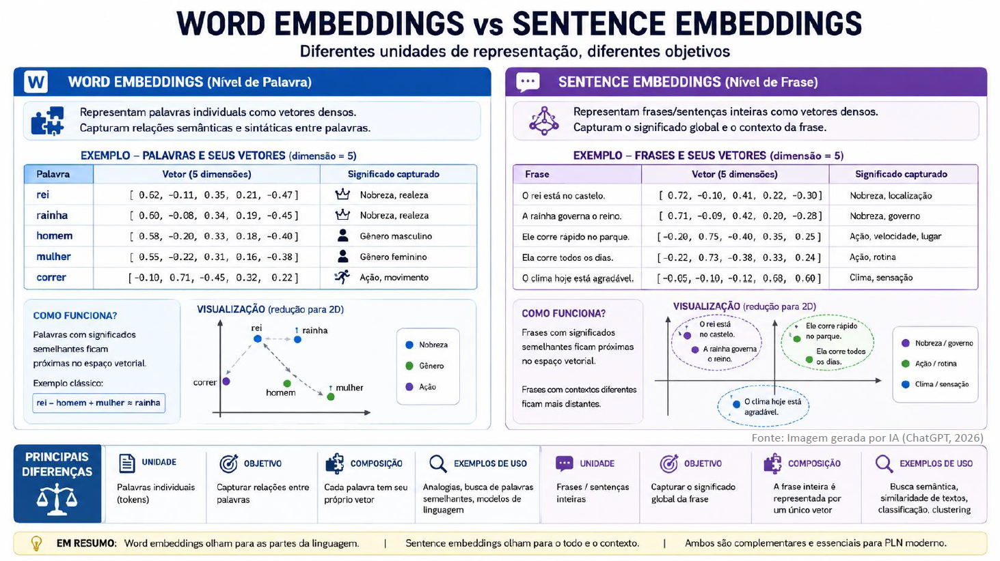

In [23]:
Image('./imagens/aula_04_005.png')

## Representando filmes como *embeddings*

Embeddings representam textos em vetores densos e procuram capturar **significado semântico**, e não apenas ocorrência das mesmas palavras.

### Criando os embeddings dos documentos

Vamos usar uma implementação prática da estratégia **SBERT (Sentence-BERT)** para a geração dos *embeddings*. O **SBERT** é uma modificação do BERT treinada para gerar embeddings de frases/documentos que podem ser comparados diretamente via similaridade de cosseno.

**embeddings**

-->A Indexação é a conversão do documento para a representação dos emmbeddings

--> é a codificação para a representação densa na forma dos vetores densos 

In [24]:
embedding_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

embeddings = embedding_model.encode(
    documents,
    normalize_embeddings=True,
    show_progress_bar=True
)

print("Shape dos embeddings:", embeddings.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/304 [00:00<?, ?it/s]

Shape dos embeddings: (9724, 384)


Exemplo de *embeddings*

Vetor agora tem 384 dimensões

Para os 9724 tem-se o Espaço vetorial de 384 termos  (384 colunas)

Cada linha é a representação vetorial de um filme. 
* o vetor tem 384 dimensões

Essa etapa corresponde a etapa de indexação dos textos em vetores densos
* Mudança de texto para a representação vetorial

* O espaço de emedding já está normalizado

In [25]:
# Reresentação de um filme --> apenas 50 colunas
embeddings[0][:50]

array([-0.05195032,  0.0008964 ,  0.01369108, -0.0178742 , -0.05732526,
        0.01231143,  0.10021123, -0.02273742,  0.01658283,  0.00623795,
        0.01199555, -0.01239485,  0.00236283,  0.07466585,  0.01629839,
        0.01649422,  0.0444535 ,  0.04087885,  0.09351385, -0.07516373,
        0.06622378,  0.00365035,  0.06792506, -0.02061084, -0.05578683,
        0.04097475, -0.00315523, -0.03034575, -0.03627604, -0.0411853 ,
        0.07654224,  0.05336829,  0.01811066, -0.03647476,  0.01251919,
        0.00491977,  0.02175978, -0.05343481, -0.02049269,  0.02522179,
       -0.05787832,  0.01002793, -0.0099698 , -0.08224727,  0.00569725,
       -0.00505874, -0.03849738, -0.08743773,  0.05573471,  0.08745057],
      dtype=float32)

##Executando consultas

**A partir dos *embeddings* gerados para cada documento, será possível executar consultas recuperando os documentos relevantes, de acordo com palavras chaves informadas pelo usuário.**

In [26]:
def search_dense(query, top_k=10):
    q_emb = embedding_model.encode(
        [query],
        normalize_embeddings=True
    )[0]

    # Como os vetores estão normalizados, produto escalar = cosseno.
    scores = embeddings @ q_emb

    ordem = np.argsort(scores)[::-1][:top_k]

    resultado = movies.iloc[ordem][["title", "genres","tags"]].copy()
    resultado["score_embedding"] = scores[ordem]

    return resultado


search_dense("toy story children", top_k=5)

,title,genres,tags,score_embedding
movieId,,,,
1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy,fun pixar,0.7675
78499,Toy Story 3,Adventure|Animation|Children|Comedy|Fantasy|IMAX,,0.7324
2253,Toys,Comedy|Fantasy,,0.7065
3114,Toy Story 2,Adventure|Animation|Children|Comedy|Fantasy,tom_hanks original pixar animation disney funny sequel,0.6901
4929,"Toy, The",Comedy,,0.6754


In [27]:
search_dense("dead man drama", top_k=5)

,title,genres,tags,score_embedding
movieId,,,,
2976,Bringing Out the Dead,Drama,,0.8231
110603,God's Not Dead,Drama,,0.7261
714,Dead Man,Drama|Mystery|Western,,0.7137
3502,My Life,Drama,death,0.6995
1382,Marked for Death,Action|Drama,,0.6955


In [28]:
search_dense("mafiax", top_k=5)

,title,genres,tags,score_embedding
movieId,,,,
858,"Godfather, The",Crime|Drama,mafia,0.6553
16,Casino,Crime|Drama,mafia,0.5910
1466,Donnie Brasco,Crime|Drama,mafia,0.5528
1221,"Godfather: Part II, The",Crime|Drama,al_pacino mafia,0.5264
431,Carlito's Way,Crime|Drama,al_pacino gangster mafia,0.5195


<font color='red'>**Pelo espaço de embeddings os erros de portugues não limitam de forma significativa o processo de busca.**</f>

## Comparando a busca lexical e semântica

In [29]:
consultas = [
    "journey through the cosmos",
    "space adventure"
]

for consulta in consultas:
    print("=" * 90)
    print("CONSULTA:", consulta)

    print("\nBM25")
    display(search_bm25(consulta, top_k=10))

    print("\nEMBEDDING")
    display(search_dense(consulta, top_k=10))

CONSULTA: journey through the cosmos

BM25


,title,genres,tags,score_bm25
movieId,,,,
171495,Cosmos,(no genres listed),,10.5282
3625,Better Living Through Circuitry,Documentary,,7.7844
2057,"Incredible Journey, The",Adventure|Children,,7.7314
77455,Exit Through the Gift Shop,Comedy|Documentary,,7.5260
3055,Felicia's Journey,Thriller,,7.3891
3100,"River Runs Through It, A",Drama,,7.2185
108715,Better Living Through Chemistry,Comedy|Drama,,7.2185
26791,Shining Through,Drama|Romance|Thriller|War,,7.2185
113275,The Hundred-Foot Journey,Comedy|Drama,,7.1694



EMBEDDING


,title,genres,tags,score_embedding
movieId,,,,
171495,Cosmos,(no genres listed),,0.4935
1231,"Right Stuff, The",Drama,nasa space,0.4675
166526,The Space Between Us,Adventure|Sci-Fi,,0.4604
128902,The Forgotten Space,Documentary,,0.4555
4813,When Worlds Collide,Sci-Fi,,0.4354
6239,Journey to the Center of the Earth,Adventure|Children|Sci-Fi,,0.4350
6302,Beginning of the End,Sci-Fi,,0.4339
8865,Sky Captain and the World of Tomorrow,Action|Adventure|Sci-Fi,,0.4318
173291,Valerian and the City of a Thousand Planets,Action|Adventure|Sci-Fi,,0.4307


CONSULTA: space adventure

BM25


,title,genres,tags,score_bm25
movieId,,,,
93610,Space Battleship Yamato,Action|Adventure|Drama,,7.7850
4812,SpaceCamp,Adventure|Sci-Fi,nasa space,7.7850
1200,Aliens,Action|Adventure|Horror|Sci-Fi,horror action space_craft sci-fi suspense space_travel aliens space,7.7690
166526,The Space Between Us,Adventure|Sci-Fi,,7.2574
3827,Space Cowboys,Action|Adventure|Comedy|Sci-Fi,,7.2574
1831,Lost in Space,Action|Adventure|Sci-Fi,,7.2574
121007,Space Buddies,Adventure|Children|Fantasy|Sci-Fi,,7.2574
128902,The Forgotten Space,Documentary,,6.8348
33493,Star Wars: Episode III - Revenge of the Sith,Action|Adventure|Sci-Fi,space_opera space,6.8342



EMBEDDING


,title,genres,tags,score_embedding
movieId,,,,
1831,Lost in Space,Action|Adventure|Sci-Fi,,0.7591
166526,The Space Between Us,Adventure|Sci-Fi,,0.7440
4812,SpaceCamp,Adventure|Sci-Fi,nasa space,0.6959
3927,Fantastic Voyage,Adventure|Sci-Fi,,0.6912
121007,Space Buddies,Adventure|Children|Fantasy|Sci-Fi,,0.6814
1200,Aliens,Action|Adventure|Horror|Sci-Fi,horror action space_craft sci-fi suspense space_travel aliens space,0.6783
6239,Journey to the Center of the Earth,Adventure|Children|Sci-Fi,,0.6714
60514,Journey to the Center of the Earth,Action|Adventure|Sci-Fi,,0.6679
1371,Star Trek: The Motion Picture,Adventure|Sci-Fi,,0.6556


**Quando o embedding encontra um resultado relevante sem compartilhar exatamente as palavras da consulta, o que ocorreu?**

- <font color = 'red'>**A recuperação deixou de depender somente da correspondência lexical e passou a explorar proximidade no espaço semântico**.</font>
- Quando usa embedding retorna resultados similares, pois entendeu que os termos possuem relação

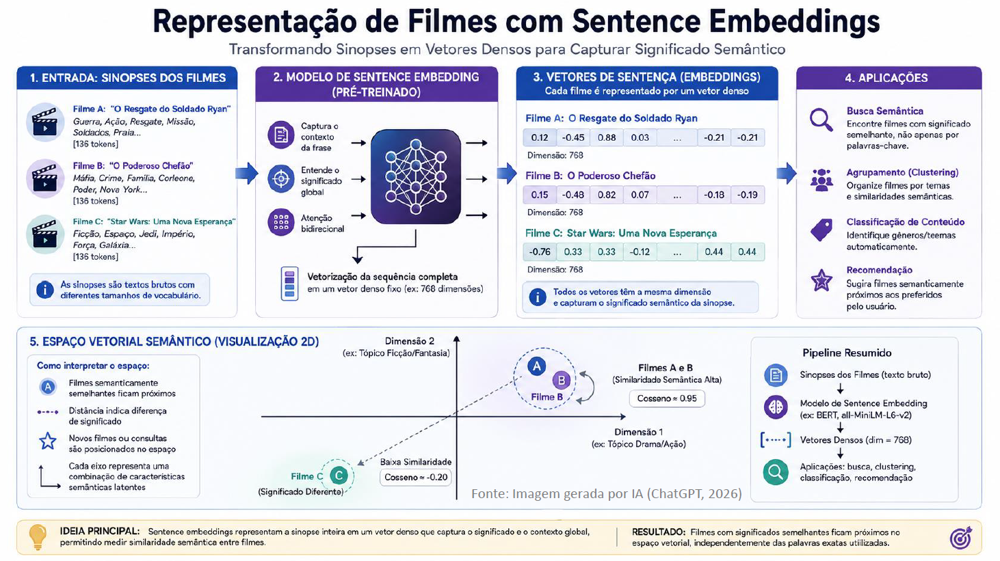

In [30]:
Image('./imagens/aula_04_006.png')

O modelo `sentence-transformers/all-MiniLM-L6-v2` converte os documentos em vetores densos de 384 dimensões.

A consulta também é convertida em embedding, e os filmes são ranqueados pela similaridade entre vetores.

<font color = 'red'>**Ponto principal:**</font> Embeddings podem recuperar conteúdos semanticamente relacionados mesmo quando a consulta e o documento não compartilham exatamente as mesmas palavras. Ainda assim, a qualidade depende do modelo, dos dados e da formulação da consulta.


# Recuperação de informação híbrida

## Executando consultas híbridas

### Por que combinar BM25 e embeddings?



Os métodos possuem pontos fortes diferentes:

```
BM25 ⇒ boa correspondência lexical exata

Embedding ⇒ boa correspondência semântica
```

**Uma recuperação híbrida tenta aproveitar as duas evidências. Busca combinar o melhor das buscas por palavras-chave e por significado**

**Processamento**

- A consulta do usuário é analisada simultaneamente por dois métodos distintos
    - Vetor Esparso (BM25): Foca na correspondência léxica exata dos termos
    - Vetor Denso (Embeddings): Captura o contexto semântico e sinônimos

**Fusão de Rankings (RRF)**

- As listas de resultados são combinadas para gerar um conjunto robusto de candidatos

**Reclassificação (Rerank)**

- Um modelo mais sofisticado avalia profundamente os top candidatos para refinar a ordem final com máxima precisão
- Entrega de uma lista final altamente relevante e ordenada para o usuário

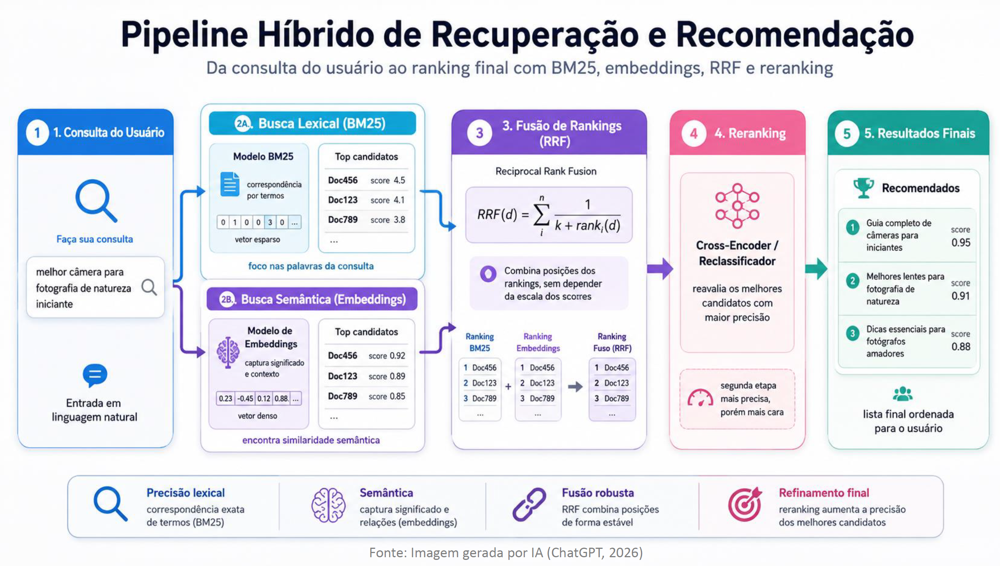

In [31]:
Image('./imagens/aula_04_007.png')

## Fusão de ranking (RRF)

### Fazendo a busca híbrida e a fusão de ranking

In [32]:
# raking especifico do bm25
def ranking_ids_bm25(query, top_k=20):
    scores = bm25.get_scores(normalizar_texto(query).split())
    ordem = np.argsort(scores)[::-1][:top_k]
    return movies.index[ordem].tolist()

In [33]:
# raking especifico do embedding
def ranking_ids_dense(query, top_k=20):
    q_emb = embedding_model.encode(
        [query],
        normalize_embeddings=True
    )[0]
    scores = embeddings @ q_emb
    ordem = np.argsort(scores)[::-1][:top_k]
    return movies.index[ordem].tolist()

In [34]:
# ranking da fusão dos dois
def reciprocal_rank_fusion(rankings, k=60):
    scores = {}

    for ranking in rankings:
        for posicao, item_id in enumerate(ranking, start=1):
            scores[item_id] = (
                scores.get(item_id, 0)
                + 1 / (k + posicao)
            )

    return sorted(
        scores.items(),
        key=lambda x: x[1],
        reverse=True
    )

### Exemplos de ranking

In [35]:
rbm25= ranking_ids_bm25('mafia',top_k=5)
rbm25

[16, 1213, 2249, 1466, 858]

In [36]:
remb = ranking_ids_dense('mafia',top_k=5)
remb

[858, 16, 1466, 1213, 99728]

In [37]:
rank_misturado = reciprocal_rank_fusion([rbm25,remb])
rank_misturado

[(16, 0.03252247488101534),
 (858, 0.03177805800756621),
 (1213, 0.031754032258064516),
 (1466, 0.03149801587301587),
 (2249, 0.015873015873015872),
 (99728, 0.015384615384615385)]

Combinação dos rankings

16 é o primeiro e o segundo dos rankings

858 e 1213 --> São primeiro e terceiro  são os primeiros 

1466 --> Terceiro no dois

### Executando consultas

In [38]:
def search_hybrid_rrf(query, top_k=10, candidates=20):
    rank_lexical = ranking_ids_bm25(query, candidates)
    rank_semantico = ranking_ids_dense(query, candidates)

    fused = reciprocal_rank_fusion(
        [rank_lexical, rank_semantico]
    )[:top_k]

    ids = [movie_id for movie_id, _ in fused]
    scores = [score for _, score in fused]

    resultado = movies.loc[ids][["title", "genres",'tags']].copy()
    resultado["score_rrf"] = scores

    return resultado


search_hybrid_rrf("toy story children", top_k=10)

,title,genres,tags,score_rrf
movieId,,,,
1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy,fun pixar,0.0328
78499,Toy Story 3,Adventure|Animation|Children|Comedy|Fantasy|IMAX,,0.0323
4929,"Toy, The",Comedy,,0.0313
3114,Toy Story 2,Adventure|Animation|Children|Comedy|Fantasy,tom_hanks original pixar animation disney funny sequel,0.0310
5843,Toy Soldiers,Action|Drama,,0.0301
1654,FairyTale: A True Story,Children|Drama|Fantasy,,0.0294
2804,"Christmas Story, A",Children|Comedy,christmas,0.0290
2253,Toys,Comedy|Fantasy,,0.0159
2161,"NeverEnding Story, The",Adventure|Children|Fantasy,,0.0152


In [39]:
search_hybrid_rrf("mafiax", top_k=10)

,title,genres,tags,score_rrf
movieId,,,,
193609,Andrew Dice Clay: Dice Rules,Comedy,,0.0164
858,"Godfather, The",Crime|Drama,mafia,0.0164
193587,Bungo Stray Dogs: Dead Apple,Action|Animation,,0.0161
16,Casino,Crime|Drama,mafia,0.0161
193585,Flint,Drama,,0.0159
1466,Donnie Brasco,Crime|Drama,mafia,0.0159
193583,No Game No Life: Zero,Animation|Comedy|Fantasy,,0.0156
1221,"Godfather: Part II, The",Crime|Drama,al_pacino mafia,0.0156
193581,Black Butler: Book of the Atlantic,Action|Animation|Comedy|Fantasy,,0.0154


In [40]:
search_hybrid_rrf("dead man drama", top_k=10)

,title,genres,tags,score_rrf
movieId,,,,
714,Dead Man,Drama|Mystery|Western,,0.0323
110603,God's Not Dead,Drama,,0.0300
2976,Bringing Out the Dead,Drama,,0.0299
336,"Walking Dead, The",Drama|War,,0.0267
2169,Dead Man on Campus,Comedy,,0.0161
40412,Dead Man's Shoes,Crime|Thriller,,0.0159
36,Dead Man Walking,Crime|Drama,death_penalty nun,0.0156
3502,My Life,Drama,death,0.0156
45722,Pirates of the Caribbean: Dead Man's Chest,Action|Adventure|Fantasy,,0.0154


### Interpretação

O RRF não tenta comparar diretamente a escala de scores do BM25 com a escala dos embeddings.

Ele combina as **posições dos itens nos rankings**. Isso é especialmente útil quando as técnicas produzem scores com significados e escalas diferentes.

A busca híbrida combina os rankings produzidos por BM25 e embeddings usando **Reciprocal Rank Fusion (RRF)**. 

Em vez de somar diretamente scores de escalas diferentes, a fusão considera a posição de cada item em cada ranking.

<font color = 'red'>**Benefício:**</font> Aproveita a correspondência lexical do BM25 e a capacidade semântica dos embeddings, sem exigir que seus scores estejam na mesma escala.

## Fazendo o Rerank

> Retriever × Reranker

### Carregando o modelo de *reranker*

In [41]:
reranker = CrossEncoder(
    'cross-encoder/ms-marco-MiniLM-L-6-v2'
)

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

### Executando consultas

In [42]:
def search_hybrid_rerank(query, top_k=10, candidates=20):
    # 1. Retriever híbrido
    candidatos = search_hybrid_rrf(
        query,
        top_k=top_k,
        candidates=candidates
    )

    ids = candidatos.index.to_list()
    docs = [documents[movies.index.get_loc(mid)] for mid in ids]

    # 2. Reranker
    pares = [[query, doc] for doc in docs]
    rr_scores = np.asarray(reranker.predict(pares))

    ordem = np.argsort(rr_scores)[::-1][:top_k]

    ids_ordenados = np.asarray(ids, dtype=object)[ordem]
    scores_ordenados = rr_scores[ordem]

    resultado = movies.loc[ids_ordenados][
        ["title", "genres", "imdb_score"]
    ].copy()

    resultado["rerank_score"] = scores_ordenados

    return resultado.sort_values(
        ["rerank_score", "imdb_score"],
        ascending=False
    )


search_hybrid_rerank("toy story children", top_k=10)

,title,genres,imdb_score,rerank_score
movieId,,,,
1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy,3.8945,5.1103
78499,Toy Story 3,Adventure|Animation|Children|Comedy|Fantasy|IMAX,3.9900,5.0979
3114,Toy Story 2,Adventure|Animation|Children|Comedy|Fantasy,3.8100,4.7554
4929,"Toy, The",Comedy,2.9894,-2.6082
2253,Toys,Comedy|Fantasy,2.6504,-3.5420
1654,FairyTale: A True Story,Children|Drama|Fantasy,3.2862,-4.0001
2161,"NeverEnding Story, The",Adventure|Children|Fantasy,3.5262,-4.2424
2804,"Christmas Story, A",Children|Comedy,3.8728,-4.8476
5843,Toy Soldiers,Action|Drama,3.0278,-5.3452


In [43]:
search_hybrid_rerank("dead man drama", top_k=10)

,title,genres,imdb_score,rerank_score
movieId,,,,
714,Dead Man,Drama|Mystery|Western,3.7026,8.2893
36,Dead Man Walking,Crime|Drama,3.7679,7.3790
2169,Dead Man on Campus,Comedy,2.8351,4.1659
2976,Bringing Out the Dead,Drama,3.3241,4.0826
40412,Dead Man's Shoes,Crime|Thriller,3.5329,3.6216
110603,God's Not Dead,Drama,2.9862,2.7001
45722,Pirates of the Caribbean: Dead Man's Chest,Action|Adventure|Fantasy,3.4798,1.8954
1382,Marked for Death,Action|Drama,2.8355,1.4183
3502,My Life,Drama,3.3218,0.5043


In [44]:
search_hybrid_rerank("mafiax", top_k=10)

,title,genres,imdb_score,rerank_score
movieId,,,,
16,Casino,Crime|Drama,3.8611,-1.4898
858,"Godfather, The",Crime|Drama,4.2431,-1.8690
1466,Donnie Brasco,Crime|Drama,3.6699,-2.2502
431,Carlito's Way,Crime|Drama,3.6542,-4.3153
1221,"Godfather: Part II, The",Crime|Drama,4.1947,-4.3858
193585,Flint,Drama,3.2862,-10.8472
193581,Black Butler: Book of the Atlantic,Action|Animation|Comedy|Fantasy,3.3362,-11.0676
193583,No Game No Life: Zero,Animation|Comedy|Fantasy,3.2862,-11.1550
193609,Andrew Dice Clay: Dice Rules,Comedy,3.3362,-11.2219


In [45]:
search_hybrid_rerank("mafia", top_k=10)

,title,genres,imdb_score,rerank_score
movieId,,,,
55765,American Gangster,Crime|Drama|Thriller,3.7796,2.6088
16,Casino,Crime|Drama,3.8611,2.1643
858,"Godfather, The",Crime|Drama,4.2431,2.0437
1466,Donnie Brasco,Crime|Drama,3.6699,1.8883
2247,Married to the Mob,Comedy,3.1125,1.5870
1213,Goodfellas,Crime|Drama,4.1842,1.5800
1245,Miller's Crossing,Crime|Drama|Film-Noir|Thriller,3.9263,1.2556
431,Carlito's Way,Crime|Drama,3.6542,1.0361
1221,"Godfather: Part II, The",Crime|Drama,4.1947,0.6987


Reordenação com reranker

Depois da recuperação híbrida, um modelo `CrossEncoder` (`cross-encoder/ms-marco-MiniLM-L-6-v2`) avalia pares formados pela consulta e pelo texto de cada candidato. 

Os candidatos são então reordenados segundo os scores do reranker.

O notebook ilustra a arquitetura **retriever + reranker**: primeiro recupera-se um conjunto limitado de candidatos; em seguida, um modelo mais direcionado à comparação entre consulta e documento refina a ordem.

# Recomendação baseada em conteúdo (não personalizada)

Considera as características dos itens para encontrar itens similares
- Título, descrição, gênero, categoria, tags, palavras chaves

Considera o user profile com as informações sobre os itens que o usuário já viu, gostou, avaliou, comprou etc.
- Explícita ou implicitamente    

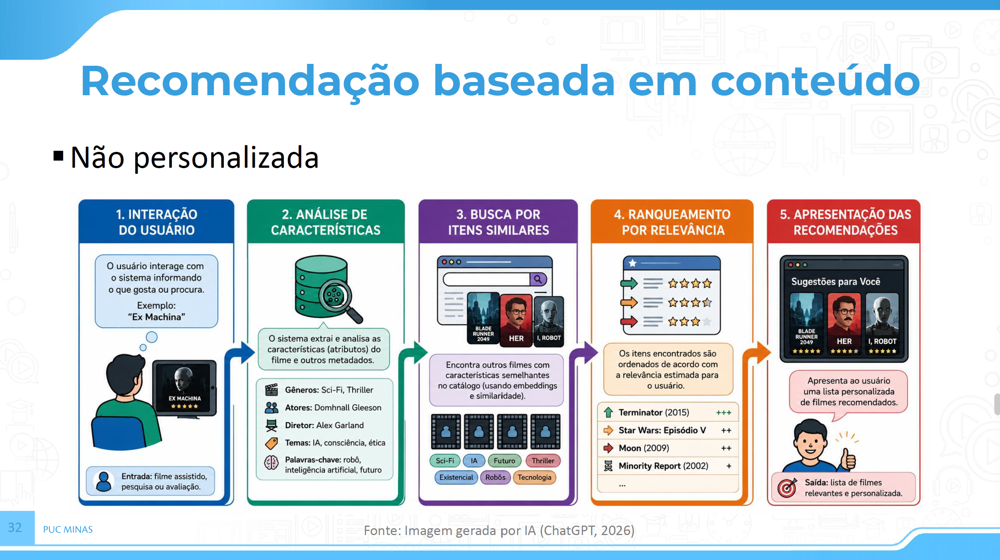

In [46]:
Image('./imagens/aula_04_008.png')

## Função de recomendação

In [47]:
def movie_document(movie_id):
    pos = movies.index.get_loc(movie_id)
    return documents[pos]


def recommend_by_content(movie_ids, top_n=10):
    if isinstance(movie_ids, (int, np.integer)):
        movie_ids = [int(movie_ids)]

    query = " ".join(
        movie_document(mid)
        for mid in movie_ids
        if mid in movies.index
    )

    candidatos = search_hybrid_rerank(
        query,
        top_k=top_n + len(movie_ids),
        candidates=max(30, top_n * 3)
    )

    candidatos = candidatos[
        ~candidatos.index.isin(movie_ids)
    ]

    return candidatos.head(top_n)

## Exemplos de recomendação

In [48]:
movie_id = 1

print("ITEM DE REFERÊNCIA")
display(movies.loc[[movie_id], ["title", "genres", "tags"]])

print("\nRECOMENDAÇÕES")
recommend_by_content(movie_id, top_n=5)

ITEM DE REFERÊNCIA


,title,genres,tags
movieId,,,
1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy,fun pixar



RECOMENDAÇÕES


,title,genres,imdb_score,rerank_score
movieId,,,,
3114,Toy Story 2,Adventure|Animation|Children|Comedy|Fantasy,3.8100,7.6572
78499,Toy Story 3,Adventure|Animation|Children|Comedy|Fantasy|IMAX,3.9900,6.6969
108932,The Lego Movie,Action|Adventure|Animation|Children|Comedy|Fantasy,3.7341,5.1389
2355,"Bug's Life, A",Adventure|Animation|Children|Comedy,3.4937,4.5289
103755,Turbo,Adventure|Animation|Children|Comedy|Fantasy,3.1862,3.1445


In [49]:
movie_ids = [1, 2355]

display(movies.loc[movie_ids, ["title", "genres"]])
recommend_by_content(movie_ids, top_n=5)

,title,genres
movieId,,
1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy
2355,"Bug's Life, A",Adventure|Animation|Children|Comedy


,title,genres,imdb_score,rerank_score
movieId,,,,
3114,Toy Story 2,Adventure|Animation|Children|Comedy|Fantasy,3.8100,5.7238
78499,Toy Story 3,Adventure|Animation|Children|Comedy|Fantasy|IMAX,3.9900,4.7741
150554,The Love Bug,Adventure|Children|Comedy|Fantasy,3.4362,2.8227
2294,Antz,Adventure|Animation|Children|Comedy|Fantasy,3.2474,2.1662
103755,Turbo,Adventure|Animation|Children|Comedy|Fantasy,3.1862,1.7885


In [50]:
movie_ids = [858]

display(movies.loc[movie_ids, ["title", "genres"]])
recommend_by_content(movie_ids, top_n=5)

,title,genres
movieId,,
858,"Godfather, The",Crime|Drama


,title,genres,imdb_score,rerank_score
movieId,,,,
1221,"Godfather: Part II, The",Crime|Drama,4.1947,8.0338
2023,"Godfather: Part III, The",Crime|Drama|Mystery|Thriller,3.3400,7.9407
1466,Donnie Brasco,Crime|Drama,3.6699,3.2895
1213,Goodfellas,Crime|Drama,4.1842,2.3174
16,Casino,Crime|Drama,3.8611,1.5695


**Recomendação baseada em conteúdo não personalizada**

A partir de um ou mais filmes de referência, o notebook monta uma consulta com os documentos correspondentes e recupera filmes semelhantes usando a busca híbrida com reranking.
    
Os próprios filmes de referência são removidos da lista de resultados.

Essa abordagem recomenda itens relacionados ao conteúdo de entrada, sem incorporar diretamente o histórico de preferências de um usuário.

# Recomendação baseada em conteúdo (personalizada)

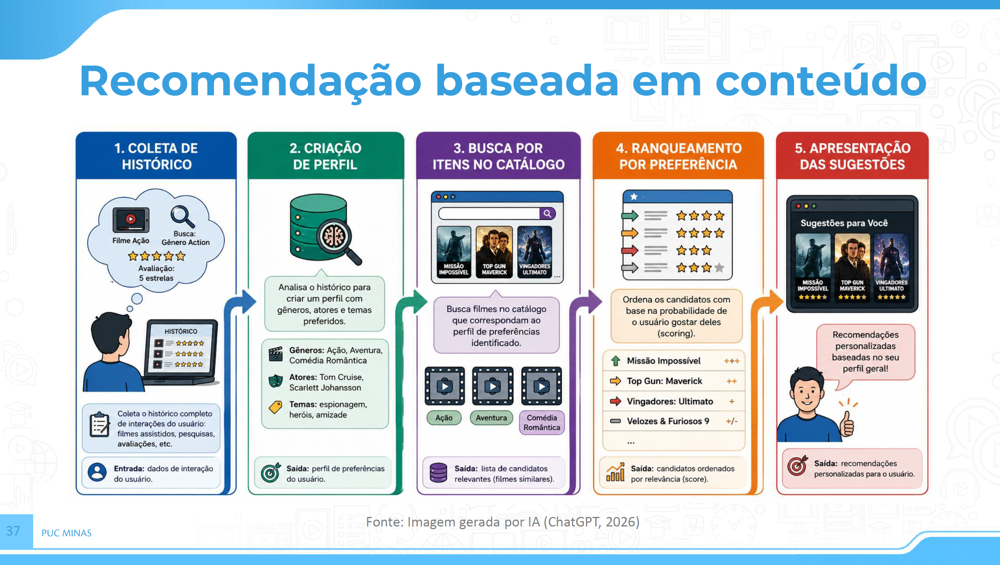

In [51]:
Image('./imagens/aula_04_009.png')

## Recomendação baseada em conteúdo com ***user profile***

A ideia do ***user profile*** é traçar o perfil de um usuário, considerando as classificações realizadas por ele para descobrir o seu ***gosto***, e depois usar estas informações para estimar a classificação de filmes ainda não vistos e encontrar recomendações ainda mais personalizadas.

É utilizado para deixar as recomendações baseadas em conteúdo personalizadas

Pode ser usado sozinho para encontrar recomendações para o usuário

Pode ser combinado com os itens similares pelo conteúdo


## Criação do ***user profile*** baseado em gêneros

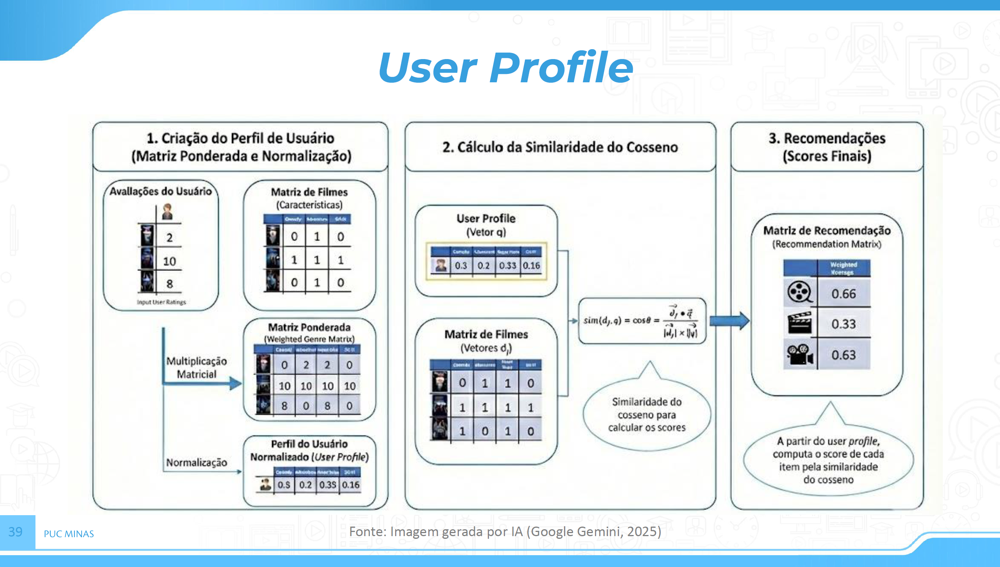

In [52]:
Image('./imagens/aula_04_010.png')

<font color = 'red'>**Representação gráfica do user profile, representando o “gosto” do usuário**</f>

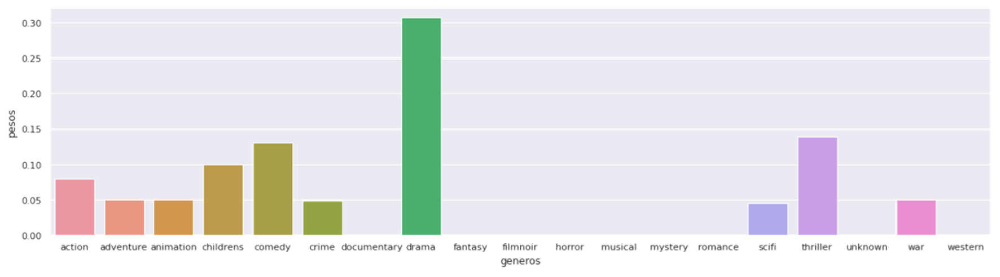

Usando o arquivo **`ratings`** para encontrar o ***gosto*** do usuário em relação a cada gênero de filme

In [53]:
ratings.head()

,userId,movieId,rating,timestamp
0,1,1,4.0000,2000-07-30 18:45:03
1,1,3,4.0000,2000-07-30 18:20:47
2,1,6,4.0000,2000-07-30 18:37:04
3,1,47,5.0000,2000-07-30 19:03:35
4,1,50,5.0000,2000-07-30 18:48:51


Mapear as características dos filmes (ex: gêneros) a serem utilizadas na montagem do ***user profile***

In [54]:
movies.head()

,title,genres,tags,tag_count,vote_count,vote_average,imdb_score
movieId,,,,,,,
1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy,fun pixar,2,215,3.9209,3.8945
2,Jumanji,Adventure|Children|Fantasy,fantasy magic_board_game game robin_williams,4,110,3.4318,3.4190
3,Grumpier Old Men,Comedy|Romance,old moldy,2,52,3.2596,3.2600
4,Waiting to Exhale,Comedy|Drama|Romance,,0,7,2.3571,2.8664
5,Father of the Bride Part II,Comedy,pregnancy remake,2,49,3.0714,3.1011


### Transformação dos gêneros para criaçao do ***user profile***

In [55]:
def transf_genero(g):
    g = str(g).lower()
    return g.replace("(no genres listed)", "unknown")


all_genres = [
    item
    for genres in movies["genres"].fillna("")
    for item in genres.split("|")
]

unique_genres = sorted({transf_genero(g) for g in all_genres if g})

movie_genres = pd.DataFrame(0.0, index=movies.index, columns=unique_genres)

for movie_id, genres in movies["genres"].fillna("").items():
    for genre in genres.split("|"):
        if genre:
            movie_genres.loc[movie_id, transf_genero(genre)] = 1.0

movie_genres.head()

,action,adventure,animation,children,comedy,crime,documentary,drama,fantasy,film-noir,horror,imax,musical,mystery,romance,sci-fi,thriller,unknown,war,western
movieId,,,,,,,,,,,,,,,,,,,,
1,0.0000,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
3,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000
4,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000
5,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


### Normalizando a contribuição de cada filme

Como um filme pode ter vários gêneros, vamos distribuir o peso do filme entre os seus gêneros para evitar que um filme com quatro gêneros possa influenciar o perfil mais que um filme com apenas um gênero.

In [56]:
movie_genres_norm = movie_genres.div(
    movie_genres.sum(axis=1).replace(0, 1),
    axis=0
)

movie_genres_norm.head()

,action,adventure,animation,children,comedy,crime,documentary,drama,fantasy,film-noir,horror,imax,musical,mystery,romance,sci-fi,thriller,unknown,war,western
movieId,,,,,,,,,,,,,,,,,,,,
1,0.0000,0.2000,0.2000,0.2000,0.2000,0.0000,0.0000,0.0000,0.2000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,0.0000,0.3333,0.0000,0.3333,0.0000,0.0000,0.0000,0.0000,0.3333,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
3,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000
4,0.0000,0.0000,0.0000,0.0000,0.3333,0.0000,0.0000,0.3333,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.3333,0.0000,0.0000,0.0000,0.0000,0.0000
5,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


Dividiu o peso 1 dos generos do filme pela quantidade de categorias de genero que o filme foi classificado.

**Filme 1**  Linha 1  

-->  Toy Story	Adventure|Animation|Children|Comedy|Fantasy	

--> Toy Story	1/5 | 1/5 | 1/5 | 1/5 | 1/5	

--> Toy Story	0.2 | 0.2 | 0.2 | 0.2 | 0.2

### Montar o ***user profile*** a partir das avaliações de um usuário

Função para criar o ***user profile*** baseado em recomendações manuais ou já avaliadas por um usuário no arquivo ***`ratings`***


In [57]:
def create_user_profile(
    user=None,
    user_ratings=None,
    positive_threshold=4.0
):
    if (user is None) == (user_ratings is None):
        raise ValueError("Informe exatamente um entre 'user' ou 'user_ratings'.")

    if user is not None:
        user_ratings = (
            ratings[
                (ratings["userId"] == user)
                & (ratings["rating"] >= positive_threshold)
            ][["movieId", "rating"]]
            .set_index("movieId")
        )
    else:
        user_ratings = user_ratings.copy()
        if "movieId" in user_ratings.columns:
            user_ratings = user_ratings.set_index("movieId")

    # Mantém somente filmes existentes na matriz de conteúdo.
    ids_validos = user_ratings.index.intersection(movie_genres_norm.index)
    user_ratings = user_ratings.loc[ids_validos]

    if len(user_ratings) == 0:
        raise ValueError("Não há avaliações positivas suficientes para criar o perfil.")

    item_features = movie_genres_norm.loc[user_ratings.index]

    weighted_features = item_features.mul(user_ratings["rating"], axis=0)

    profile = weighted_features.sum(axis=0)

    if profile.sum() > 0:
        profile = profile / profile.sum()

    return profile

A função combina três conceitos importantes:
1. Seleção de avaliações positivas: considera filmes com nota igual ou superior a positive_threshold.
2. Representação dos itens: utiliza a matriz movie_genres_norm para representar cada filme por seus gêneros.
3. Construção do perfil: agrega os vetores dos filmes avaliados, ponderando-os pelas notas atribuídas pelo usuário.

Pontos importantes na implementação

**As notas funcionam como pesos absolutos**

Isso significa que um filme avaliado com nota 5 tem mais influência do que um filme avaliado com nota 4.

É uma estratégia válida, mas existe uma particularidade: uma nota 5 não representa necessariamente uma preferência 25% maior do que uma nota 4.

Uma alternativa seria ponderar os filmes pela intensidade da preferência acima de um ponto de referência,

$$
w_{ui} = r_{ui} - 3
$$

Nesse caso, uma nota 5 teria peso 2 e uma nota 4 teria peso 1.

Essa alternativa muda o significado do perfil.

Não existe uma escolha universalmente correta: é importante definir o que os pesos devem representar.


**A normalização dos vetores dos filmes importa**

Você utiliza movie_genres_norm, mas o comportamento depende de como essa matriz foi construída.

Se ela contém indicadores binários de gêneros, a soma ponderada funciona como uma contagem de preferências por gênero.

Se os vetores foram normalizados por norma L2, a soma de seus componentes pode ser diferente para cada filme.
    
Nesse caso, a agregação pode ter outra interpretação.

**O alinhamento dos índices**    

Ele restringe os dados aos filmes que possuem características disponíveis.

Entretanto, vale garantir que movieId seja único no índice de user_ratings e em movie_genres_norm. 

Se houver avaliações repetidas para um mesmo filme, a agregação poderá produzir resultados inesperados.

In [58]:
avaliacoes_exemplo = pd.DataFrame(
    {
        "movieId": [1, 2, 3],
        "rating": [4.5, 5.0, 4.0]
    }
)

perfil_exemplo = create_user_profile( user_ratings=avaliacoes_exemplo )
perfil_exemplo

action        0.0000
adventure     0.1901
animation     0.0667
children      0.1901
comedy        0.2148
crime         0.0000
documentary   0.0000
drama         0.0000
fantasy       0.1901
film-noir     0.0000
horror        0.0000
imax          0.0000
musical       0.0000
mystery       0.0000
romance       0.1481
sci-fi        0.0000
thriller      0.0000
unknown       0.0000
war           0.0000
western       0.0000
dtype: float64

### Representação gráfica do ***user profile***

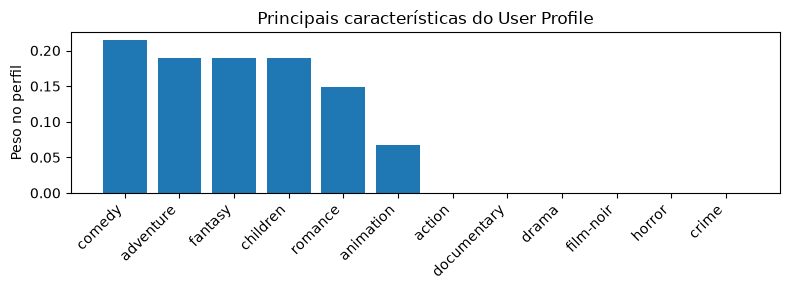

In [59]:
def plot_user_profile(profile, top_n=12):
    dados = profile.sort_values(ascending=False).head(top_n)
    plt.figure(figsize=(8, 3))
    plt.bar(dados.index, dados.values)
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Peso no perfil")
    plt.title("Principais características do User Profile")
    plt.tight_layout()
    plt.show()

plot_user_profile(perfil_exemplo)

### *User profile* para um usuário específico

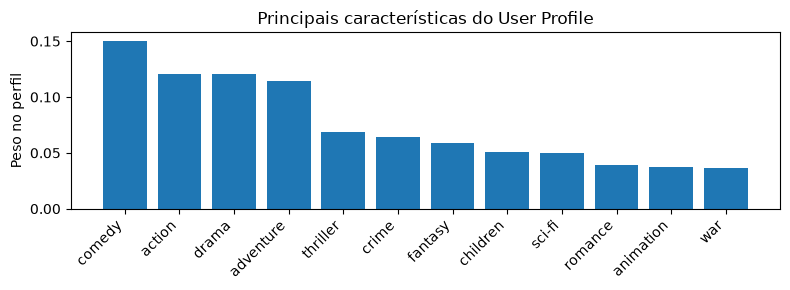

In [60]:
plot_user_profile(
    create_user_profile(user=1) )

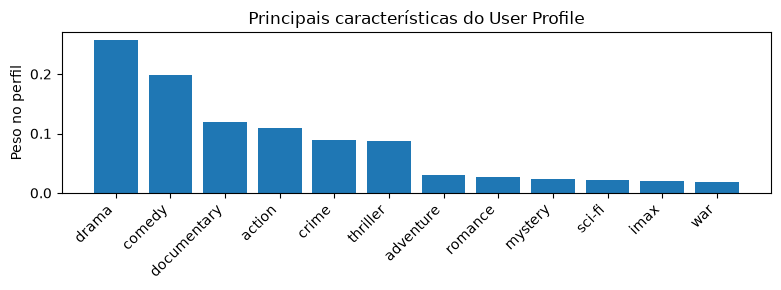

In [61]:
plot_user_profile(
    create_user_profile(user=2)
)


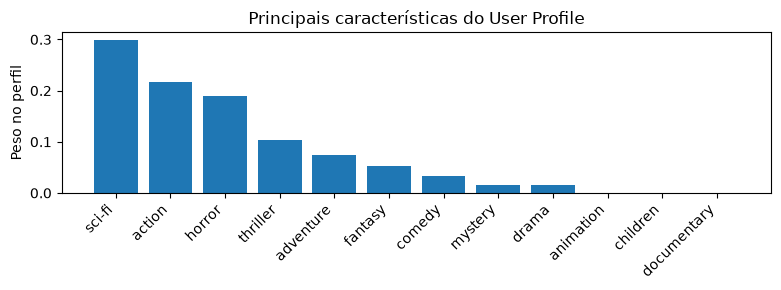

In [62]:
plot_user_profile(
    create_user_profile(user=3)
)


### Cálculo do score de cada filme de acordo com o ***user profile***

Com o ***user profile***, será possível calcular o *score* de cada filme para o usuário

In [63]:
def user_profile_scores(profile):
    scores = cosine_similarity(
        movie_genres_norm.values,
        [profile.values]
    )[:, 0]

    resultado = movies[
        ["title", "genres", "imdb_score"]
    ].copy()

    resultado["user_profile_score"] = scores

    return resultado


user_profile_scores( create_user_profile(user=3) )\
    .sort_values("user_profile_score", ascending=False).head(10)

,title,genres,imdb_score,user_profile_score
movieId,,,,
170289,Species III,Action|Horror|Sci-Fi,3.0362,0.9274
160565,The Purge: Election Year,Action|Horror|Sci-Fi,3.1693,0.9274
173307,The Gracefield Incident,Action|Horror|Sci-Fi,2.9862,0.9274
2614,Chopping Mall (a.k.a. Killbots),Action|Horror|Sci-Fi,2.8511,0.9274
56801,AVPR: Aliens vs. Predator - Requiem,Action|Horror|Sci-Fi,2.9908,0.9274
54995,Planet Terror,Action|Horror|Sci-Fi,3.6407,0.9274
3576,"Hidden, The",Action|Horror|Sci-Fi,3.3355,0.9274
1762,Deep Rising,Action|Horror|Sci-Fi,2.9187,0.9274
2525,Alligator,Action|Horror|Sci-Fi,2.9468,0.9274


In [64]:
# Recomendação para o usuario 1
user_profile_scores( create_user_profile(user=1) )\
    .sort_values("user_profile_score", ascending=False).head(10)

,title,genres,imdb_score,user_profile_score
movieId,,,,
117646,Dragonheart 2: A New Beginning,Action|Adventure|Comedy|Drama|Fantasy|Thriller,3.3862,0.8698
55116,"Hunting Party, The",Action|Adventure|Comedy|Drama|Thriller,3.1135,0.8642
6990,The Great Train Robbery,Action|Adventure|Comedy|Crime|Drama,3.2862,0.8575
5657,Flashback,Action|Adventure|Comedy|Crime|Drama,3.3862,0.8575
4818,Extreme Days,Action|Adventure|Comedy|Drama,3.1362,0.8503
4956,"Stunt Man, The",Action|Adventure|Comedy|Drama|Romance|Thriller,3.5718,0.8429
42015,Casanova,Action|Adventure|Comedy|Drama|Romance,3.1968,0.8197
2890,Three Kings,Action|Adventure|Comedy|Drama|War,3.6363,0.8150
82765,Little Big Soldier (Da bing xiao jiang),Action|Adventure|Comedy|Drama|War,3.2862,0.8150


## Recomendações baseadas no ***user profile***

Criar a função **`recommend_by_user_profile()`** para encontrar recomendações baseadas no ***user profile***

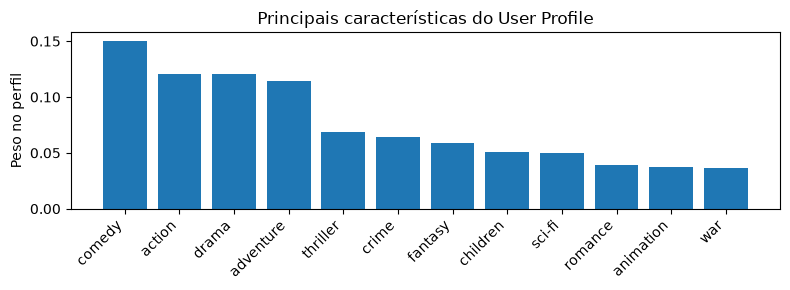

,title,genres,imdb_score,user_profile_score
movieId,,,,
117646,Dragonheart 2: A New Beginning,Action|Adventure|Comedy|Drama|Fantasy|Thriller,3.3862,0.8698
55116,"Hunting Party, The",Action|Adventure|Comedy|Drama|Thriller,3.1135,0.8642
5657,Flashback,Action|Adventure|Comedy|Crime|Drama,3.3862,0.8575
6990,The Great Train Robbery,Action|Adventure|Comedy|Crime|Drama,3.2862,0.8575
4818,Extreme Days,Action|Adventure|Comedy|Drama,3.1362,0.8503
4956,"Stunt Man, The",Action|Adventure|Comedy|Drama|Romance|Thriller,3.5718,0.8429
42015,Casanova,Action|Adventure|Comedy|Drama|Romance,3.1968,0.8197
2890,Three Kings,Action|Adventure|Comedy|Drama|War,3.6363,0.8150
82765,Little Big Soldier (Da bing xiao jiang),Action|Adventure|Comedy|Drama|War,3.2862,0.8150


In [65]:
def recommend_by_user_profile(user, top_n=10):
    profile = create_user_profile(user=user)

    resultado = user_profile_scores(profile)

    vistos = set(
        ratings.loc[
            ratings["userId"] == user,
            "movieId"
        ]
    )

    resultado = resultado[
        ~resultado.index.isin(vistos)
    ]

    return resultado.sort_values(
        ["user_profile_score", "imdb_score"],
        ascending=False
    ).head(top_n)


USER_ID = 1
plot_user_profile(create_user_profile(user=USER_ID))
recommend_by_user_profile(USER_ID, top_n=10)

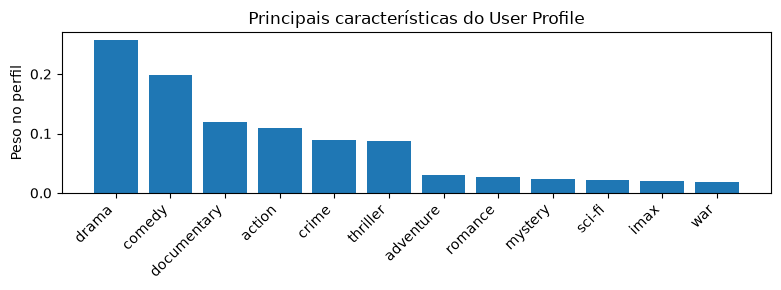

,title,genres,imdb_score,user_profile_score
movieId,,,,
8464,Super Size Me,Comedy|Documentary|Drama,3.4722,0.8553
27899,What the #$*! Do We Know!? (a.k.a. What the Bleep Do We Know!?),Comedy|Documentary|Drama,3.1693,0.8553
7007,"Last Boy Scout, The",Action|Comedy|Crime|Drama|Thriller,3.3742,0.8542
5628,Wasabi,Action|Comedy|Crime|Drama|Thriller,3.3473,0.8542
145,Bad Boys,Action|Comedy|Crime|Drama|Thriller,3.2477,0.8542
5027,Another 48 Hrs.,Action|Comedy|Crime|Drama|Thriller,3.1687,0.8542
1432,Metro,Action|Comedy|Crime|Drama|Thriller,3.0226,0.8542
20,Money Train,Action|Comedy|Crime|Drama|Thriller,2.7859,0.8542
8370,"Blind Swordsman: Zatoichi, The (ZatÃ´ichi)",Action|Comedy|Crime|Drama,3.6601,0.8426


In [66]:
USER_ID = 2
plot_user_profile(create_user_profile(user=USER_ID))
recommend_by_user_profile(USER_ID, top_n=10)

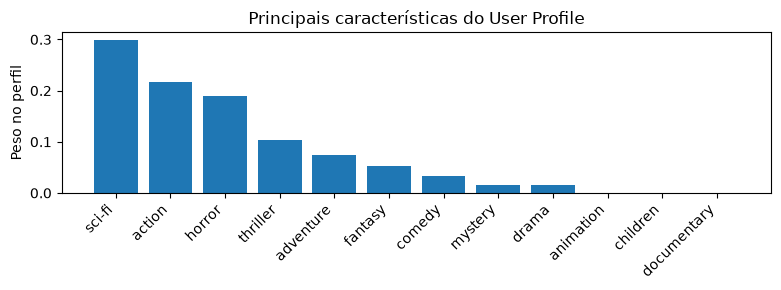

,title,genres,imdb_score,user_profile_score
movieId,,,,
6502,28 Days Later,Action|Horror|Sci-Fi,3.8785,0.9274
54995,Planet Terror,Action|Horror|Sci-Fi,3.6407,0.9274
3576,"Hidden, The",Action|Horror|Sci-Fi,3.3355,0.9274
128542,Wyrmwood,Action|Horror|Sci-Fi,3.2862,0.9274
27003,Beowulf,Action|Horror|Sci-Fi,3.2362,0.9274
8500,Godzilla vs. Mechagodzilla (Gojira tai Mekagojira),Action|Horror|Sci-Fi,3.1862,0.9274
160565,The Purge: Election Year,Action|Horror|Sci-Fi,3.1693,0.9274
158956,Kill Command,Action|Horror|Sci-Fi,3.1238,0.9274
34292,Hardware,Action|Horror|Sci-Fi,3.0862,0.9274


In [67]:
USER_ID = 3
plot_user_profile(create_user_profile(user=USER_ID))
recommend_by_user_profile(USER_ID, top_n=10)

## Recomendações de um filme para um usuário

In [68]:
def recommend_item_for_user(
    movie_id,
    user,
    alpha=0.6,
    top_n=10
):

    # Similaridade com o item de referência
    ref_pos = movies.index.get_loc(movie_id)
    ref_embedding = embeddings[ref_pos]

    item_scores = embeddings @ ref_embedding

    # Perfil do usuário baseado em gêneros
    genre_profile = create_user_profile(user=user)

    # Garante que as colunas estejam na mesma ordem
    genre_profile = genre_profile.reindex(
        movie_genres_norm.columns,
        fill_value=0
    )

    # Similaridade/afinidade dos filmes com o perfil de gêneros
    user_scores = (
        movie_genres_norm
        @ genre_profile
    )

    # Combinação dos dois critérios
    score_final = (
        alpha * item_scores
        + (1 - alpha) * user_scores.values
    )

    # Construção do resultado
    resultado = movies[
        ["title", "genres", "imdb_score"]
    ].copy()

    resultado["item_similarity"] = item_scores

    resultado["genre_profile_similarity"] = (
        user_scores.reindex(resultado.index).values
    )

    resultado["score_final"] = score_final

    # Remove filmes já avaliados pelo usuário
    vistos = set(
        ratings.loc[
            ratings["userId"] == user,
            "movieId"
        ]
    )

    vistos.add(movie_id)

    resultado = resultado[ ~resultado.index.isin(vistos) ]

    return resultado.sort_values(
        ["score_final", "imdb_score"],
        ascending=False
    ).head(top_n)

Versão não personalizada

In [69]:
MOVIE_ID = 1

display(movies.loc[[MOVIE_ID], ["title", "genres"]])

recommend_by_content([MOVIE_ID])

,title,genres
movieId,,
1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy


,title,genres,imdb_score,rerank_score
movieId,,,,
3114,Toy Story 2,Adventure|Animation|Children|Comedy|Fantasy,3.8100,7.6572
78499,Toy Story 3,Adventure|Animation|Children|Comedy|Fantasy|IMAX,3.9900,6.6969
108932,The Lego Movie,Action|Adventure|Animation|Children|Comedy|Fantasy,3.7341,5.1389
2355,"Bug's Life, A",Adventure|Animation|Children|Comedy,3.4937,4.5289
45074,"Wild, The",Adventure|Animation|Children|Comedy|Fantasy,3.1862,4.0422
134853,Inside Out,Adventure|Animation|Children|Comedy|Drama|Fantasy,3.7185,3.8886
2294,Antz,Adventure|Animation|Children|Comedy|Fantasy,3.2474,3.7450
4886,"Monsters, Inc.",Adventure|Animation|Children|Comedy|Fantasy,3.8324,3.7300
103755,Turbo,Adventure|Animation|Children|Comedy|Fantasy,3.1862,3.1445


Versão personalizada

In [70]:
USER_ID = 1
recommend_item_for_user(MOVIE_ID, user=USER_ID, top_n=5)

,title,genres,imdb_score,item_similarity,genre_profile_similarity,score_final
movieId,,,,,,
3114,Toy Story 2,Adventure|Animation|Children|Comedy|Fantasy,3.8100,0.8477,0.0824,0.5415
78499,Toy Story 3,Adventure|Animation|Children|Comedy|Fantasy|IMAX,3.9900,0.8540,0.0686,0.5398
108932,The Lego Movie,Action|Adventure|Animation|Children|Comedy|Fantasy,3.7341,0.8375,0.0888,0.5380
103755,Turbo,Adventure|Animation|Children|Comedy|Fantasy,3.1862,0.8215,0.0824,0.5258
2355,"Bug's Life, A",Adventure|Animation|Children|Comedy,3.4937,0.8149,0.0882,0.5242


In [71]:
USER_ID = 3
recommend_item_for_user(MOVIE_ID, user=USER_ID, top_n=5)

,title,genres,imdb_score,item_similarity,genre_profile_similarity,score_final
movieId,,,,,,
108932,The Lego Movie,Action|Adventure|Animation|Children|Comedy|Fantasy,3.7341,0.8375,0.0626,0.5276
78499,Toy Story 3,Adventure|Animation|Children|Comedy|Fantasy|IMAX,3.9900,0.8540,0.0265,0.5230
3114,Toy Story 2,Adventure|Animation|Children|Comedy|Fantasy,3.8100,0.8477,0.0318,0.5213
103755,Turbo,Adventure|Animation|Children|Comedy|Fantasy,3.1862,0.8215,0.0318,0.5056
130520,Home,Adventure|Animation|Children|Comedy|Fantasy|Sci-Fi,3.2566,0.7894,0.0763,0.5042


In [72]:
USER_ID = 4
recommend_item_for_user(MOVIE_ID, user=USER_ID, top_n=5, alpha=0.6)

,title,genres,imdb_score,item_similarity,genre_profile_similarity,score_final
movieId,,,,,,
3114,Toy Story 2,Adventure|Animation|Children|Comedy|Fantasy,3.8100,0.8477,0.0678,0.5357
78499,Toy Story 3,Adventure|Animation|Children|Comedy|Fantasy|IMAX,3.9900,0.8540,0.0565,0.5350
2253,Toys,Comedy|Fantasy,2.6504,0.7913,0.1353,0.5289
108932,The Lego Movie,Action|Adventure|Animation|Children|Comedy|Fantasy,3.7341,0.8375,0.0618,0.5272
103755,Turbo,Adventure|Animation|Children|Comedy|Fantasy,3.1862,0.8215,0.0678,0.5200


In [73]:
USER_ID = 4
recommend_item_for_user(MOVIE_ID, user=USER_ID, top_n=5, alpha=0.1)

,title,genres,imdb_score,item_similarity,genre_profile_similarity,score_final
movieId,,,,,,
5963,"Children's Hour, The",Drama,3.3056,0.4425,0.2832,0.2991
166643,Hidden Figures,Drama,3.5454,0.4395,0.2832,0.2989
4470,Ariel,Drama,3.2147,0.4197,0.2832,0.2969
134214,Youth,Drama,3.3355,0.4135,0.2832,0.2962
2310,"Mighty, The",Drama,3.3635,0.4042,0.2832,0.2953


Recomendação personalizada com perfil do usuário

O perfil do usuário (`user profile`) é construído a partir dos gêneros dos filmes que ele avaliou positivamente.
    
Para evitar que filmes com muitos gêneros tenham peso desproporcional, a contribuição de cada filme é distribuída entre seus gêneros.

O perfil é então comparado com a representação de gêneros dos filmes para estimar afinidade. O notebook também implementa uma recomendação que combina:

- **similaridade com o filme de referência**, calculada por embeddings;
- **afinidade com o perfil do usuário**, calculada a partir dos gêneros;
- um parâmetro `alpha` para controlar a contribuição relativa dos dois sinais.

###  Efeito do parâmetro α

Quando o `α` for 1, *não* considera o perfil

Quando o `α` for 0, considera *somente* o perfil

In [74]:
for alpha in [1.0, 0.8, 0.6, 0.4, 0.2, 0.0]:
    print("=" * 90)
    print(f"alpha = {alpha}")

    display(
        recommend_item_for_user(
            MOVIE_ID,
            user=USER_ID,
            alpha=alpha,
            top_n=3
        )
    )

alpha = 1.0


,title,genres,imdb_score,item_similarity,genre_profile_similarity,score_final
movieId,,,,,,
78499,Toy Story 3,Adventure|Animation|Children|Comedy|Fantasy|IMAX,3.9900,0.8540,0.0565,0.8540
3114,Toy Story 2,Adventure|Animation|Children|Comedy|Fantasy,3.8100,0.8477,0.0678,0.8477
108932,The Lego Movie,Action|Adventure|Animation|Children|Comedy|Fantasy,3.7341,0.8375,0.0618,0.8375


alpha = 0.8


,title,genres,imdb_score,item_similarity,genre_profile_similarity,score_final
movieId,,,,,,
78499,Toy Story 3,Adventure|Animation|Children|Comedy|Fantasy|IMAX,3.9900,0.8540,0.0565,0.6945
3114,Toy Story 2,Adventure|Animation|Children|Comedy|Fantasy,3.8100,0.8477,0.0678,0.6917
108932,The Lego Movie,Action|Adventure|Animation|Children|Comedy|Fantasy,3.7341,0.8375,0.0618,0.6824


alpha = 0.6


...

,title,genres,imdb_score,item_similarity,genre_profile_similarity,score_final
movieId,,,,,,
4929,"Toy, The",Comedy,2.9894,0.6701,0.2397,0.4118
2253,Toys,Comedy|Fantasy,2.6504,0.7913,0.1353,0.3977
3308,"Flamingo Kid, The",Comedy|Drama,3.0851,0.5876,0.2614,0.3919


alpha = 0.2


,title,genres,imdb_score,item_similarity,genre_profile_similarity,score_final
movieId,,,,,,
3308,"Flamingo Kid, The",Comedy|Drama,3.0851,0.5876,0.2614,0.3267
4929,"Toy, The",Comedy,2.9894,0.6701,0.2397,0.3258
3310,"Kid, The",Comedy|Drama,3.5616,0.5732,0.2614,0.3238


alpha = 0.0


,title,genres,imdb_score,item_similarity,genre_profile_similarity,score_final
movieId,,,,,,
1193,One Flew Over the Cuckoo's Nest,Drama,4.1434,0.2371,0.2832,0.2832
1276,Cool Hand Luke,Drama,4.1343,0.1681,0.2832,0.2832
1104,"Streetcar Named Desire, A",Drama,4.0987,0.1954,0.2832,0.2832


Na implementação, `alpha = 1` considera somente a similaridade com o filme de referência, enquanto `alpha = 0` considera somente a afinidade com o perfil de gêneros.
    
Valores intermediários combinam os dois critérios.